In [11]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

In [2]:
df = pd.read_csv("student_dataset_10000_rows.csv")

print(df.head())
print(df.shape)

   study_hours  attendance  sleep_hours  internet_usage  \
0            7          56            8               7   
1            4          69            5               3   
2           11          60            7               6   
3            8          99            9               8   
4            5          52            8               6   

   assignments_completed  previous_score  exam_score placement_status  
0                     10              62      100.00           Placed  
1                      8              56      100.00           Placed  
2                     10              45      100.00           Placed  
3                      4              55       90.17           Placed  
4                      8              40       78.82           Placed  
(10000, 8)


In [3]:
X = df[[
    "study_hours","attendance","sleep_hours","internet_usage","assignments_completed","previous_score"
]]

y = df["exam_score"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 6)
y shape: (10000,)


In [4]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8000, 6)
X_test: (2000, 6)
y_train: (8000,)
y_test: (2000,)


In [5]:
model = LinearRegression()
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [6]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[104.48363625  86.34312059  88.7366549   76.23368636  91.13056421
 102.42832056  92.76107442  91.56024231  99.42902362  97.51450857]


In [8]:
comparison = pd.DataFrame({
    "Actual score" : y_test.values,
    "Predicted score" : y_pred
})
print(comparison.head(10))

   Actual score  Predicted score
0        100.00       104.483636
1         84.07        86.343121
2         95.37        88.736655
3         83.96        76.233686
4         78.58        91.130564
5        100.00       102.428321
6         83.98        92.761074
7         93.85        91.560242
8        100.00        99.429024
9        100.00        97.514509


In [10]:
MAE = mean_absolute_error(y_test,y_pred)
print("Mean Absolute Error:", MAE)

Mean Absolute Error: 6.917285717910664


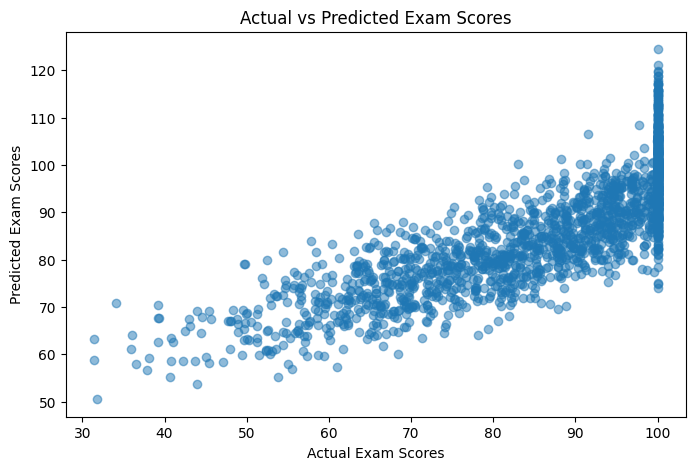

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")

plt.title("Actual vs Predicted Exam Scores")

plt.show()

In [19]:
# Calculate additional evaluation metrics

from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", MAE)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 6.917285717910664
MSE: 77.31965170367613
RMSE: 8.793159369855418
R2 Score: 0.6634458623051923


In [20]:
print("Predictions below 0:", (y_pred < 0).sum())
print("Predictions above 100:", (y_pred > 100).sum())

Predictions below 0: 0
Predictions above 100: 293


In [21]:
print("Actual exam score range:")
print("Minimum:", y.min())
print("Maximum:", y.max())

print("\nTest score range:")
print("Minimum:", y_test.min())
print("Maximum:", y_test.max())

print("\nPrediction range:")
print("Minimum:", y_pred.min())
print("Maximum:", y_pred.max())

Actual exam score range:
Minimum: 26.67
Maximum: 100.0

Test score range:
Minimum: 31.41
Maximum: 100.0

Prediction range:
Minimum: 50.49430689585415
Maximum: 124.44500004601537


In [25]:
# Find predictions greater than 100

invalid_predictions = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": y_pred
})

invalid_predictions = invalid_predictions[
    invalid_predictions["Predicted Score"] > 100
]

print(invalid_predictions.head(50))

     Actual Score  Predicted Score
0          100.00       104.483636
5          100.00       102.428321
10         100.00       104.367832
12          98.32       103.569378
16         100.00       112.621924
29         100.00       101.130093
39         100.00       105.450105
42         100.00       100.830054
46         100.00       103.174834
50         100.00       100.547619
52         100.00       113.554051
66         100.00       103.952847
82         100.00       105.986838
83         100.00       103.661613
87         100.00       108.178288
110        100.00       107.361759
112        100.00       104.108091
116        100.00       100.627980
123        100.00       107.257676
138        100.00       112.619005
144        100.00       105.000134
149        100.00       106.880031
154        100.00       103.220131
157        100.00       100.978884
171        100.00       106.655938
185        100.00       102.033500
186        100.00       105.464342
199        100.00   